# T01 · Data Handling & Visualization (Import · Inspect · Select · Filter · Set Role · Join · Concatenate · Pivot · Charts)

**ใช้เมื่อโจทย์ถาม:** อ่านไฟล์/ตรวจข้อมูล · สรุปสถิติ · เลือก/ตัดคอลัมน์ · กรองแถว · ตั้ง id/label · ต่อตาราง (append/concat) · join/merge ·
group by / aggregate · pivot table · สร้างคอลัมน์ใหม่ · วาดกราฟ (histogram, boxplot, bar, scatter, heatmap) + ตีความ

| ขั้น | ทำอะไร |
|---|---|
| 1 | แก้ **⚙️ CONFIG** (cell ถัดไป) — path ไฟล์ + ชื่อคอลัมน์ |
| 2 | **Run All** (หรือรันทีละ cell จากบนลงล่าง) |
| 3 | ไปเฉพาะ § ที่โจทย์ถาม → แก้บรรทัดที่มี `# ✏️` ใน cell นั้น → รันใหม่ |
| 4 | copy ประโยค `✍️` ที่พิมพ์ออกมา + เติมใน cell **คำตอบ** · ลบ § ที่ไม่ใช้ก่อนส่ง |

> ทุก § ใช้ตัวแปร `df` (ข้อมูลหลัก) ต่อกันเป็นทอด ๆ — ถ้าข้าม § ไหนก็ไม่เป็นไร ยกเว้น §1 ต้องรันเสมอ

In [1]:
# ════════ ⚙️ CONFIG — แก้ cell นี้ให้ตรงโจทย์ ════════
DATA_PATH   = "../practice/data/p1_bills_week1.csv"   # ไฟล์หลัก (.csv / .xlsx / .xls)
DATA_PATH_2 = "../practice/data/p1_bills_week2.csv"   # ไฟล์ที่จะ "ต่อแถว" (concatenate/append) — ไม่มีใส่ None
LOOKUP_PATH = "../practice/data/p1_day_info.csv"      # ไฟล์ที่จะ "join" เข้ามา — ไม่มีใส่ None
JOIN_KEY    = "day"          # คอลัมน์ที่ใช้จับคู่ (ชื่อต่างกัน 2 ฝั่ง → ใส่ tuple เช่น ("cust_id", "id"))
JOIN_HOW    = "left"         # "inner" = เฉพาะที่ตรงกัน · "left" = เก็บทุกแถวของไฟล์หลัก · "outer" = เก็บทั้งหมด
ID_COL      = "bill_id"      # คอลัมน์ id (ไม่มีใส่ None)
TARGET      = "tip"          # คอลัมน์ที่โจทย์สนใจ/label (ไม่มีใส่ None)
SHEET       = 0              # ชื่อ/ลำดับ sheet ถ้าเป็น Excel
CSV_SEP     = ","            # ตัวคั่น csv (บางไฟล์ใช้ ";")
MISSING_MARKERS = ["?", "", " ", "NA", "N/A", "null", "-"]   # ค่าที่แปลว่า "ว่าง" ในไฟล์นี้
SEED = 42

In [2]:
# ════════ 🔧 IMPORTS + HELPERS — ไม่ต้องแก้ cell นี้ แค่รันหลัง CONFIG ════════
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder,
                                   KBinsDiscretizer, LabelEncoder)
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import (DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, silhouette_samples, davies_bouldin_score)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# ค่า default ถ้า CONFIG ไม่ได้กำหนดไว้ (กันลืม)
for _name, _val in {"SEED": 42, "N_FOLDS": 5, "TEST_SIZE": 0.2, "TARGET": None, "POS_LABEL": None,
                    "ID_COL": None, "DROP_COLS": [], "MISSING_MARKERS": ["?", "", " ", "NA", "N/A", "null"],
                    "SHEET": 0, "CSV_SEP": ",", "SCALE": "standard"}.items():
    globals().setdefault(_name, _val)


def load_data(path, sheet=None, sep=None, na_values=None):
    """อ่าน .csv / .xlsx / .xls → ตัดช่องว่างหัวคอลัมน์และค่า string → แปลงค่าแฝง ('?', '') เป็น NaN"""
    sheet = SHEET if sheet is None else sheet
    sep = CSV_SEP if sep is None else sep
    na_values = MISSING_MARKERS if na_values is None else na_values
    if str(path).lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, sheet_name=sheet)
    else:
        df = pd.read_csv(path, sep=sep)
    df.columns = [str(c).strip() for c in df.columns]
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            df[c] = df[c].map(lambda v: v.strip() if isinstance(v, str) else v)
    df = df.replace(list(na_values), np.nan)
    # คอลัมน์ที่เป็นตัวเลขแต่ถูกอ่านเป็น text (เพราะเคยมี '?') → แปลงกลับเป็นตัวเลข
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            conv = pd.to_numeric(df[c], errors="coerce")
            if conv.notna().sum() == df[c].notna().sum() and df[c].notna().any():
                df[c] = conv
    print(f"โหลด {path} → {df.shape[0]} แถว × {df.shape[1]} คอลัมน์")
    return df


def check(df, target=None):
    """ตรวจข้อมูลใน 1 คำสั่ง: ขนาด · ชนิด · ค่าว่าง · unique · ตัวอย่างค่า · สัดส่วน target"""
    print("shape:", df.shape, "| แถวซ้ำ:", int(df.duplicated().sum()))
    info = pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "missing": df.isna().sum(),
                         "missing_%": (df.isna().mean() * 100).round(2),
                         "unique": df.nunique(),
                         "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df]})
    display(info)
    if target is not None and target in df and pd.api.types.is_numeric_dtype(df[target]) and df[target].nunique() > 15:
        print(f"target '{target}' เป็นตัวเลข (regression):")
        display(df[target].describe().to_frame().T)
    elif target is not None and target in df:
        vc = pd.concat([df[target].value_counts(dropna=False), df[target].value_counts(normalize=True, dropna=False).round(4)],
                       axis=1, keys=["count", "ratio"])
        print(f"การกระจายของ target '{target}':")
        display(vc)


def num_cols(df):
    return df.select_dtypes(include="number").columns.tolist()


def cat_cols(df):
    return [c for c in df.columns if c not in num_cols(df)]


def make_xy(df, target=None, drop=None, pos_label=None, task="classification"):
    """แยก X / y · ตัด target + DROP_COLS + ID_COL · classification 2 คลาส → y = 1 ถ้าเท่ากับ POS_LABEL"""
    target = TARGET if target is None else target
    drop = DROP_COLS if drop is None else drop
    pos_label = POS_LABEL if pos_label is None else pos_label
    d = df.dropna(subset=[target]).copy()
    removed = [c for c in list(drop) + [ID_COL] if c is not None and c in d.columns and c != target]
    X = d.drop(columns=[target] + removed)
    if task == "regression":
        y = d[target].astype(float)
        print(f"X: {X.shape} | y = '{target}' (ตัวเลข) | ตัดคอลัมน์: {removed}")
        return X, y
    raw = d[target]
    classes = sorted(raw.astype(str).unique())
    if len(classes) == 2:
        pos = str(pos_label) if pos_label is not None else classes[-1]
        if pos not in classes:
            raise ValueError(f"POS_LABEL={pos_label!r} ไม่อยู่ใน {classes} — แก้ใน CONFIG")
        neg = [c for c in classes if c != pos][0]
        y = (raw.astype(str) == pos).astype(int).rename(target)
        print(f"X: {X.shape} | y = '{target}' → 1 = {pos!r} (positive), 0 = {neg!r} | ตัดคอลัมน์: {removed}")
    else:
        y = raw.astype(str)
        print(f"X: {X.shape} | y = '{target}' มี {len(classes)} คลาส {classes} (multiclass → ใช้ macro avg) | ตัดคอลัมน์: {removed}")
    return X, y


def is_binary(y):
    return pd.Series(y).nunique() == 2


def build_prep(X, scale=None, num_impute="median", onehot=True):
    """preprocessing ที่ fit เฉพาะ train (ใส่ใน Pipeline → ไม่ leak)
    ตัวเลข: เติมค่าว่าง (median) → scale ('standard' z-score | 'minmax' 0–1 | None)
    หมวดหมู่: เติมค่าว่าง (ค่าที่พบบ่อยสุด) → one-hot"""
    scale = SCALE if scale is None else scale
    nums, cats = num_cols(X), cat_cols(X)
    scaler = {"standard": StandardScaler(), "minmax": MinMaxScaler()}.get(scale, "passthrough")
    num_pipe = Pipeline([("impute", SimpleImputer(strategy=num_impute)), ("scale", scaler)])
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False) if onehot else \
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", enc)])
    return ColumnTransformer([("num", num_pipe, nums), ("cat", cat_pipe, cats)],
                             verbose_feature_names_out=False)


def make_pipe(model, X, scale=None, **kw):
    """Pipeline = preprocessing (fit บน train fold เท่านั้น) + model"""
    return Pipeline([("prep", build_prep(X, scale=scale, **kw)), ("model", model)])


def get_cv(task="classification", n=None):
    n = N_FOLDS if n is None else n
    if task == "regression":
        return KFold(n_splits=n, shuffle=True, random_state=SEED)
    return StratifiedKFold(n_splits=n, shuffle=True, random_state=SEED)


def cls_scoring(y):
    if is_binary(y):
        return {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}
    return {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"}


def evaluate(name, model, X, y, cv=None, settings="", train=False):
    """classification ด้วย cross-validation → 1 แถว (ค่าเฉลี่ยทุก fold) ใช้ต่อเป็นตารางเปรียบเทียบ"""
    cv = get_cv() if cv is None else cv
    r = cross_validate(model, X, y, cv=cv, scoring=cls_scoring(y), return_train_score=train)
    row = {"model": name, "settings": settings}
    row.update({m: r[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1"]})
    row["f1_std"] = r["test_f1"].std()
    if train:
        row["train_accuracy"] = r["train_accuracy"].mean()
    return row


def evaluate_holdout(name, model, X_tr, y_tr, X_te, y_te, settings=""):
    """classification แบบ hold-out: fit บน train → วัดบน test"""
    model.fit(X_tr, y_tr)
    p = model.predict(X_te)
    avg = "binary" if is_binary(y_tr) else "macro"
    return {"model": name, "settings": settings,
            "accuracy": accuracy_score(y_te, p),
            "precision": precision_score(y_te, p, average=avg, zero_division=0),
            "recall": recall_score(y_te, p, average=avg, zero_division=0),
            "f1": f1_score(y_te, p, average=avg, zero_division=0),
            "train_accuracy": accuracy_score(y_tr, model.predict(X_tr))}


def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse, "RMSE": np.sqrt(mse),
            "R2": r2_score(y_true, y_pred)}


def evaluate_reg(name, model, X, y, cv=None, settings=""):
    """regression ด้วย cross-validation → MAE / MSE / RMSE / R²"""
    cv = get_cv("regression") if cv is None else cv
    r = cross_validate(model, X, y, cv=cv,
                       scoring=["neg_mean_absolute_error", "neg_mean_squared_error", "r2"])
    mse = -r["test_neg_mean_squared_error"].mean()
    return {"model": name, "settings": settings, "MAE": -r["test_neg_mean_absolute_error"].mean(),
            "MSE": mse, "RMSE": np.sqrt(mse), "R2": r["test_r2"].mean()}


def show_cm(y_true, y_pred, title="Confusion matrix"):
    """confusion matrix (แถว = actual, คอลัมน์ = predicted) + classification report"""
    labels = sorted(pd.Series(y_true).unique(), key=str)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    display(pd.DataFrame(cm, index=[f"actual {l}" for l in labels], columns=[f"pred {l}" for l in labels]))
    if len(labels) == 2:
        tn, fp, fn, tp = cm.ravel()
        print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))
    fig, ax = plt.subplots(figsize=(4, 3.4))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title); ax.grid(False); plt.show()
    return cm


def top_k(grid, n=10):
    """ตารางผล GridSearchCV เรียงจากดีสุด"""
    res = pd.DataFrame(grid.cv_results_)
    cols = [c for c in res if c.startswith("param_")] + \
           [c for c in res if c.startswith("mean_test_") or c.startswith("mean_train_")]
    key = f"mean_test_{grid.refit}" if isinstance(grid.refit, str) else "mean_test_score"
    return res[cols].sort_values(key, ascending=False).head(n).reset_index(drop=True)


def results_table(rows, sort_by=None, ascending=False):
    t = pd.DataFrame(rows)
    if sort_by:
        t = t.sort_values(sort_by, ascending=ascending)
    display(t.reset_index(drop=True))
    return t.reset_index(drop=True)


def say_compare(table, metric="f1", baseline_name=None, higher_is_better=True):
    """พิมพ์ประโยคตีความสำเร็จรูปจากตารางผล (copy ไปใส่คำตอบได้เลย)"""
    t = table.sort_values(metric, ascending=not higher_is_better)
    best = t.iloc[0]
    msg = f"✍️ โมเดลที่ดีที่สุดตาม {metric} คือ {best['model']}"
    if str(best.get("settings", "")):
        msg += f" ({best['settings']})"
    msg += f" ได้ {metric} = {best[metric]:.4f}"
    if baseline_name is not None and baseline_name in set(table["model"]):
        b = table.loc[table["model"] == baseline_name].iloc[0]
        diff = best[metric] - b[metric]
        msg += f" เทียบกับ baseline ({baseline_name}) ที่ได้ {b[metric]:.4f} ต่างกัน {diff:+.4f}"
        if "accuracy" in table and metric != "accuracy":
            msg += f" (baseline accuracy = {b['accuracy']:.4f} แต่ {metric} ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)"
    print(msg)


def new_data(source):
    """ข้อมูลใหม่ที่จะทำนาย: path ไฟล์ (str) / dict 1 แถว / list ของ dict / DataFrame"""
    if source is None:
        return None
    if isinstance(source, str):
        return load_data(source)
    if isinstance(source, dict):
        return pd.DataFrame([source])
    if isinstance(source, list):
        return pd.DataFrame(source)
    return source.copy()


def align_new(df_new, X_ref):
    """จัดคอลัมน์ข้อมูลใหม่ให้ตรงกับ X ที่ใช้ train (คอลัมน์ที่ขาดเติม NaN → imputer จัดการ)"""
    missing = [c for c in X_ref.columns if c not in df_new.columns]
    if missing:
        print("⚠️ ข้อมูลใหม่ขาดคอลัมน์:", missing, "→ เติม NaN (imputer จะเติมให้)")
    return df_new.reindex(columns=X_ref.columns)

print("✅ helpers พร้อม | SEED =", SEED, "| N_FOLDS =", N_FOLDS)

✅ helpers พร้อม | SEED = 42 | N_FOLDS = 5


## §1 Import + ตรวจข้อมูล (Inspect) — **รันเสมอ**
โจทย์: *"import ข้อมูลและตรวจสอบ · มีกี่แถว/คอลัมน์ · ชนิดข้อมูล · ค่าว่าง · สรุปสถิติ"*

In [3]:
df = load_data(DATA_PATH)
display(df.head())
check(df, TARGET)

โหลด ../practice/data/p1_bills_week1.csv → 130 แถว × 8 คอลัมน์


,bill_id,total_bill,tip,sex,smoker,day,time,size
0,2,10.3400,1.6600,Male,No,Sun,Dinner,3
1,3,21.0100,3.5000,Male,No,Sun,Dinner,3
2,6,25.2900,4.7100,Male,No,Sun,Dinner,4
3,9,15.0400,1.9600,Male,No,Sun,Dinner,2
4,10,14.7800,3.2300,Male,No,Sun,Dinner,2


shape: (130, 8) | แถวซ้ำ: 0


,dtype,missing,missing_%,unique,example
bill_id,int64,0,0.0000,130,2
total_bill,float64,0,0.0000,122,10.3400
tip,float64,0,0.0000,73,1.6600
sex,str,0,0.0000,2,Male
smoker,str,0,0.0000,2,No
day,str,0,0.0000,4,Sun
time,str,0,0.0000,2,Dinner
size,int64,0,0.0000,6,3


target 'tip' เป็นตัวเลข (regression):


,count,mean,std,min,25%,50%,75%,max
tip,130.0000,3.0223,1.4417,1.0000,2.0000,2.8150,3.7025,9.0000


In [4]:
# สรุปสถิติ: ตัวเลข (mean, std, min, quartiles, max) และหมวดหมู่ (count, unique, top, freq)
display(df.describe().T)
if cat_cols(df):
    display(df[cat_cols(df)].describe().T)
# ค่าที่ต่างจากปกติ: skew > 1 = เบ้ขวามาก (mean > median)
skew = df[num_cols(df)].skew().sort_values(ascending=False)
print("skewness:\n", skew.round(3).to_string())

,count,mean,std,min,25%,50%,75%,max
bill_id,130.0000,122.4769,72.7481,2.0000,59.2500,119.0000,185.7500,243.0000
total_bill,130.0000,19.7254,9.3688,3.0700,12.9575,17.5300,23.7550,48.3300
tip,130.0000,3.0223,1.4417,1.0000,2.0000,2.8150,3.7025,9.0000
size,130.0000,2.6077,0.9523,1.0000,2.0000,2.0000,3.0000,6.0000


,count,unique,top,freq
sex,130,2,Male,93
smoker,130,2,No,81
day,130,4,Sat,49
time,130,2,Dinner,101


skewness:
 tip          1.2240
size         1.1350
total_bill   1.0900
bill_id      0.0300


**✍️ คำตอบ §1:** ข้อมูลมี … แถว … คอลัมน์ (ตัวเลข … / หมวดหมู่ …) · ค่าว่างอยู่ที่ … (…%) · `…` มี mean … median … → เบ้ขวา/สมมาตร ·
target มีสัดส่วน … → สมดุล/ไม่สมดุล

## §2 Select Attributes (เลือก/ตัดคอลัมน์) + Set Role
- **Select** = เลือกเฉพาะคอลัมน์ที่ใช้ · **ตัด** = id, คอลัมน์ที่เป็นคำตอบล่วงหน้า (leak), คอลัมน์ซ้ำซ้อน, ค่าว่างเยอะ
- **Set Role** ใน Python = ตั้ง `id` เป็น index และแยก `X` (attributes) กับ `y` (label)

In [5]:
KEEP_COLS = None                 # ✏️ list ของคอลัมน์ที่ "เก็บ" เช่น ["total_bill", "tip", "day"] · None = เก็บทั้งหมด
DROP_THESE = []                  # ✏️ list ของคอลัมน์ที่ "ตัด" เช่น ["size"]
BY_TYPE = None                   # ✏️ "number" = เก็บเฉพาะตัวเลข · "category" = เฉพาะหมวดหมู่ · None = ไม่กรองตามชนิด

sel = df.copy()
if KEEP_COLS is not None:
    sel = sel[[c for c in KEEP_COLS if c in sel.columns] + [c for c in [ID_COL, TARGET] if c and c in sel and c not in KEEP_COLS]]
sel = sel.drop(columns=[c for c in DROP_THESE if c in sel.columns])
if BY_TYPE == "number":
    sel = sel[[c for c in sel.columns if c in num_cols(sel) or c in (ID_COL, TARGET)]]
elif BY_TYPE == "category":
    sel = sel[[c for c in sel.columns if c in cat_cols(sel) or c in (ID_COL, TARGET)]]
print("คอลัมน์ก่อน:", df.shape[1], "→ หลัง:", sel.shape[1])
print("เหลือ:", list(sel.columns))

# ---- Set Role ----
roled = sel.set_index(ID_COL) if ID_COL and ID_COL in sel else sel
if TARGET and TARGET in roled:
    X_role, y_role = roled.drop(columns=[TARGET]), roled[TARGET]
    print(f"id = {ID_COL} (index) | label = {TARGET} | attributes = {list(X_role.columns)}")
display(roled.head())

คอลัมน์ก่อน: 8 → หลัง: 8
เหลือ: ['bill_id', 'total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']
id = bill_id (index) | label = tip | attributes = ['total_bill', 'sex', 'smoker', 'day', 'time', 'size']


,total_bill,tip,sex,smoker,day,time,size
bill_id,,,,,,,
2,10.3400,1.6600,Male,No,Sun,Dinner,3
3,21.0100,3.5000,Male,No,Sun,Dinner,3
6,25.2900,4.7100,Male,No,Sun,Dinner,4
9,15.0400,1.9600,Male,No,Sun,Dinner,2
10,14.7800,3.2300,Male,No,Sun,Dinner,2


**✍️ คำตอบ §2:** ตัด `…` เพราะเป็นรหัส (id) ไม่มีความหมายเชิงทำนาย / เป็นข้อมูลที่รู้หลังเกิดผล (leakage) / ซ้ำกับ `…` · ตั้ง `…` เป็น label

## §3 Filter Examples (กรองแถว)
เขียนเงื่อนไขแบบ pandas `query` · ตัวอย่าง:
`"total_bill > 20"` · `"smoker == 'Yes' and day in ['Sat','Sun']"` · `"tip >= 2 or size > 4"` · `"`ชื่อมีเว้นวรรค` > 5"` (ชื่อคอลัมน์มีช่องว่างใช้ backtick)

In [6]:
FILTER = "total_bill > 20 and smoker == 'Yes'"     # ✏️ เงื่อนไข
DROP_MISSING_ROWS_IN = []                          # ✏️ ตัดแถวที่คอลัมน์เหล่านี้ว่าง (= Filter: is not missing)

flt = df.query(FILTER) if FILTER else df.copy()
if DROP_MISSING_ROWS_IN:
    flt = flt.dropna(subset=DROP_MISSING_ROWS_IN)
print(f"แถวก่อนกรอง {len(df)} → หลังกรอง {len(flt)} ({len(flt)/len(df):.1%})")
display(flt.head())
# ตัวอย่างเงื่อนไขแบบอื่น (ไม่ใช้ query):
#   df[df["day"].isin(["Sat", "Sun"])]          df[df["total_bill"].between(10, 20)]
#   df[df["name"].str.contains("abc", na=False)] df[df["col"].isna()]  /  .notna()

แถวก่อนกรอง 130 → หลังกรอง 22 (16.9%)


,bill_id,total_bill,tip,sex,smoker,day,time,size
31,57,38.0100,3.0000,Male,Yes,Sat,Dinner,4
45,84,32.6800,5.0000,Male,Yes,Thur,Lunch,2
53,96,40.1700,4.7300,Male,Yes,Fri,Dinner,4
54,99,21.0100,3.0000,Male,Yes,Fri,Dinner,2
58,104,22.4200,3.4800,Female,Yes,Sat,Dinner,2


**✍️ คำตอบ §3:** กรองเงื่อนไข `…` เหลือ … แถวจาก … แถว (…%)

## §4 Concatenate / Append (ต่อแถว — ไฟล์คอลัมน์เดียวกัน เช่นข้อมูลคนละช่วงเวลา)
ต่อ `df` (ไฟล์หลัก) + `DATA_PATH_2` · ตรวจว่าคอลัมน์ตรงกัน · ใส่คอลัมน์ `source` บอกว่ามาจากไฟล์ไหน

In [7]:
if DATA_PATH_2:
    df2 = load_data(DATA_PATH_2)
    only1, only2 = set(df.columns) - set(df2.columns), set(df2.columns) - set(df.columns)
    print("คอลัมน์ที่มีแค่ไฟล์ 1:", only1 or "-", "| มีแค่ไฟล์ 2:", only2 or "-")
    both = pd.concat([df.assign(source="file1"), df2.assign(source="file2")], ignore_index=True)
    print(f"ต่อแถว: {len(df)} + {len(df2)} = {len(both)} แถว | คอลัมน์ {both.shape[1]}")
    dup_id = both[ID_COL].duplicated().sum() if ID_COL and ID_COL in both else both.duplicated().sum()
    print("id/แถวซ้ำหลังต่อ:", int(dup_id), "(ถ้า > 0 พิจารณา both.drop_duplicates(...))")
    display(both["source"].value_counts())
    df = both.drop(columns="source")          # ✏️ ใช้ข้อมูลที่ต่อแล้วเป็น df หลักต่อจากนี้ (ไม่ต้องการ → comment บรรทัดนี้)
else:
    print("ไม่มี DATA_PATH_2 → ข้าม §4")

โหลด ../practice/data/p1_bills_week2.csv → 114 แถว × 8 คอลัมน์
คอลัมน์ที่มีแค่ไฟล์ 1: - | มีแค่ไฟล์ 2: -
ต่อแถว: 130 + 114 = 244 แถว | คอลัมน์ 9
id/แถวซ้ำหลังต่อ: 0 (ถ้า > 0 พิจารณา both.drop_duplicates(...))


source
file1    130
file2    114
Name: count, dtype: int64

**✍️ คำตอบ §4:** ใช้ concatenate (append) เพราะสองไฟล์มีคอลัมน์เดียวกัน เป็นข้อมูลคนละช่วง → ได้ … แถว

## §5 Join / Merge (เพิ่มคอลัมน์จากอีกตารางด้วย key)
| how | ผล | ใช้เมื่อ |
|---|---|---|
| `inner` | เฉพาะ key ที่มีทั้งสองตาราง | ต้องการเฉพาะแถวที่ข้อมูลครบ |
| `left` | ทุกแถวของตารางหลัก (ไม่เจอคู่ → NaN) | ห้ามแถวหลักหาย (นิยมสุด) |
| `outer` | ทุกแถวทั้งสองฝั่ง | ดูว่าอะไรไม่จับคู่ |

In [8]:
if LOOKUP_PATH:
    lk = load_data(LOOKUP_PATH)
    lkey, rkey = (JOIN_KEY if isinstance(JOIN_KEY, tuple) else (JOIN_KEY, JOIN_KEY))
    print(f"ก่อน join: หลัก {df.shape} | lookup {lk.shape} | key ซ้ำใน lookup: {int(lk[rkey].duplicated().sum())}")
    joined = df.merge(lk, left_on=lkey, right_on=rkey, how=JOIN_HOW, indicator=True,
                      suffixes=("", "_lookup"))
    display(joined["_merge"].value_counts().rename({"both": "จับคู่ได้", "left_only": "มีแค่ตารางหลัก",
                                                    "right_only": "มีแค่ lookup"}))
    joined = joined.drop(columns="_merge")
    if rkey != lkey and rkey in joined:
        joined = joined.drop(columns=rkey)
    print(f"หลัง join ({JOIN_HOW}): {joined.shape}")
    display(joined.head())
    df = joined                                # ✏️ ใช้ผล join เป็น df หลักต่อจากนี้
else:
    print("ไม่มี LOOKUP_PATH → ข้าม §5")

โหลด ../practice/data/p1_day_info.csv → 4 แถว × 3 คอลัมน์
ก่อน join: หลัก (244, 8) | lookup (4, 3) | key ซ้ำใน lookup: 0


_merge
จับคู่ได้         244
มีแค่ตารางหลัก      0
มีแค่ lookup        0
Name: count, dtype: int64

หลัง join (left): (244, 10)


,bill_id,total_bill,tip,sex,smoker,day,time,size,is_weekend,open_hours
0,2,10.3400,1.6600,Male,No,Sun,Dinner,3,Yes,12
1,3,21.0100,3.5000,Male,No,Sun,Dinner,3,Yes,12
2,6,25.2900,4.7100,Male,No,Sun,Dinner,4,Yes,12
3,9,15.0400,1.9600,Male,No,Sun,Dinner,2,Yes,12
4,10,14.7800,3.2300,Male,No,Sun,Dinner,2,Yes,12


**✍️ คำตอบ §5:** join แบบ `…` ด้วย key `…` เพราะ … (ต้องเก็บทุกแถวของตารางหลัก / เอาเฉพาะที่ตรงกัน) · ก่อน … แถว × … คอลัมน์ → หลัง … × … · จับคู่ไม่ได้ … แถว

## §6 Aggregate / Group by
สรุปตามกลุ่ม: count, mean, sum, min, max, median, std

In [9]:
GROUP_BY = ["day"]                                    # ✏️ จัดกลุ่มตาม (1 หรือหลายคอลัมน์)
AGG = {"total_bill": ["count", "mean", "sum"], "tip": ["mean", "max"]}   # ✏️ คอลัมน์: [ฟังก์ชัน]

agg = df.groupby(GROUP_BY).agg(AGG)
agg.columns = ["_".join(c) for c in agg.columns]       # ชื่อคอลัมน์แบบชั้นเดียว เช่น total_bill_mean
agg = agg.reset_index().sort_values(agg.columns[1], ascending=False)
display(agg)

,day,total_bill_count,total_bill_mean,total_bill_sum,tip_mean,tip_max
2,Sun,76,21.4100,"1,627.1600",3.2551,6.5000
1,Sat,87,20.4414,"1,778.4000",2.9931,10.0000
3,Thur,62,17.6827,"1,096.3300",2.7715,6.7000
0,Fri,19,17.1516,325.8800,2.7347,4.7300


**✍️ คำตอบ §6:** กลุ่ม `…` มีค่าเฉลี่ย `…` สูงสุด (…) ต่ำสุดคือ … (…)

## §7 Pivot table / Crosstab
- `pivot_table` = แถว × คอลัมน์ × ค่า (aggregate) · `crosstab` = นับจำนวน/สัดส่วน 2 ตัวแปรหมวดหมู่
- **สัดส่วนของคลาสหนึ่ง** (เช่น % income >50K ตาม education × gender) → สร้างคอลัมน์ 0/1 แล้ว pivot ด้วย `mean`

In [10]:
PIV_INDEX, PIV_COLUMNS, PIV_VALUES, PIV_FUNC = "day", "time", "tip", "mean"   # ✏️ แถว, คอลัมน์, ค่า, ฟังก์ชัน (mean/sum/count/max)
RATE_OF = None                 # ✏️ หา "สัดส่วน" ของคลาส เช่น ("income", ">50K") → ใช้แทน PIV_VALUES · None = ไม่ใช้

data_p = df.copy()
values = PIV_VALUES
if RATE_OF:
    data_p["_rate"] = (data_p[RATE_OF[0]].astype(str) == str(RATE_OF[1])).astype(int)
    values, PIV_FUNC = "_rate", "mean"
pv = pd.pivot_table(data_p, index=PIV_INDEX, columns=PIV_COLUMNS, values=values, aggfunc=PIV_FUNC,
                    margins=True, margins_name="All")
display(pv.round(4))

# crosstab: จำนวน + สัดส่วนตามแถว (แต่ละแถวรวม = 1)
display(pd.crosstab(df[PIV_INDEX], df[PIV_COLUMNS], margins=True))
display(pd.crosstab(df[PIV_INDEX], df[PIV_COLUMNS], normalize="index").round(3))
# pivot กลับ (wide → long): pv.reset_index().melt(id_vars=PIV_INDEX)

time,Dinner,Lunch,All
day,,,
Fri,2.9400,2.3829,2.7347
Sat,2.9931,NaN,2.9931
Sun,3.2551,NaN,3.2551
Thur,3.0000,2.7677,2.7715
All,3.1027,2.7281,2.9983


time,Dinner,Lunch,All
day,,,
Fri,12,7,19
Sat,87,0,87
Sun,76,0,76
Thur,1,61,62
All,176,68,244


time,Dinner,Lunch
day,,
Fri,0.6320,0.3680
Sat,1.0000,0.0000
Sun,1.0000,0.0000
Thur,0.0160,0.9840


**✍️ คำตอบ §7:** จาก pivot `…` × `…` ค่า `…` สูงสุดที่ … = … ต่ำสุดที่ … = … → แสดงว่า …

## §8 Generate Attributes (สร้างคอลัมน์ใหม่) + แปลงชนิด

In [11]:
# ✏️ แก้/เพิ่มสูตรตามโจทย์
df["tip_pct"] = df["tip"] / df["total_bill"] * 100                          # คำนวณจากคอลัมน์อื่น
df["big_bill"] = np.where(df["total_bill"] > df["total_bill"].median(), "Yes", "No")   # if-else
df["bill_level"] = pd.cut(df["total_bill"], bins=[0, 15, 30, np.inf], labels=["low", "mid", "high"])  # แบ่งช่วง
# df["date"] = pd.to_datetime(df["date"]); df["month"] = df["date"].dt.month   # วันที่
# df["col"] = df["col"].astype(float)  /  .astype(str)                       # แปลงชนิด
# df = df.rename(columns={"old": "new"})                                     # เปลี่ยนชื่อ
display(df.head())

,bill_id,total_bill,tip,sex,smoker,day,time,size,is_weekend,open_hours,tip_pct,big_bill,bill_level
0,2,10.3400,1.6600,Male,No,Sun,Dinner,3,Yes,12,16.0542,No,low
1,3,21.0100,3.5000,Male,No,Sun,Dinner,3,Yes,12,16.6587,Yes,mid
2,6,25.2900,4.7100,Male,No,Sun,Dinner,4,Yes,12,18.6240,Yes,mid
3,9,15.0400,1.9600,Male,No,Sun,Dinner,2,Yes,12,13.0319,No,mid
4,10,14.7800,3.2300,Male,No,Sun,Dinner,2,Yes,12,21.8539,No,low


## §9 กราฟพื้นฐาน + ตีความ
| อยากดู | กราฟ |
|---|---|
| การกระจายของตัวเลข 1 ตัว | histogram (+KDE) / boxplot |
| ตัวเลข เทียบระหว่างกลุ่ม | boxplot แยกกลุ่ม / bar ค่าเฉลี่ย |
| จำนวนในแต่ละหมวด / สัดส่วนคลาส | bar (countplot) / stacked bar |
| ความสัมพันธ์ตัวเลข 2 ตัว | scatter (+สีตามคลาส) |
| ความสัมพันธ์หลายตัวพร้อมกัน | correlation heatmap / pairplot |
| แนวโน้มตามเวลา | line |

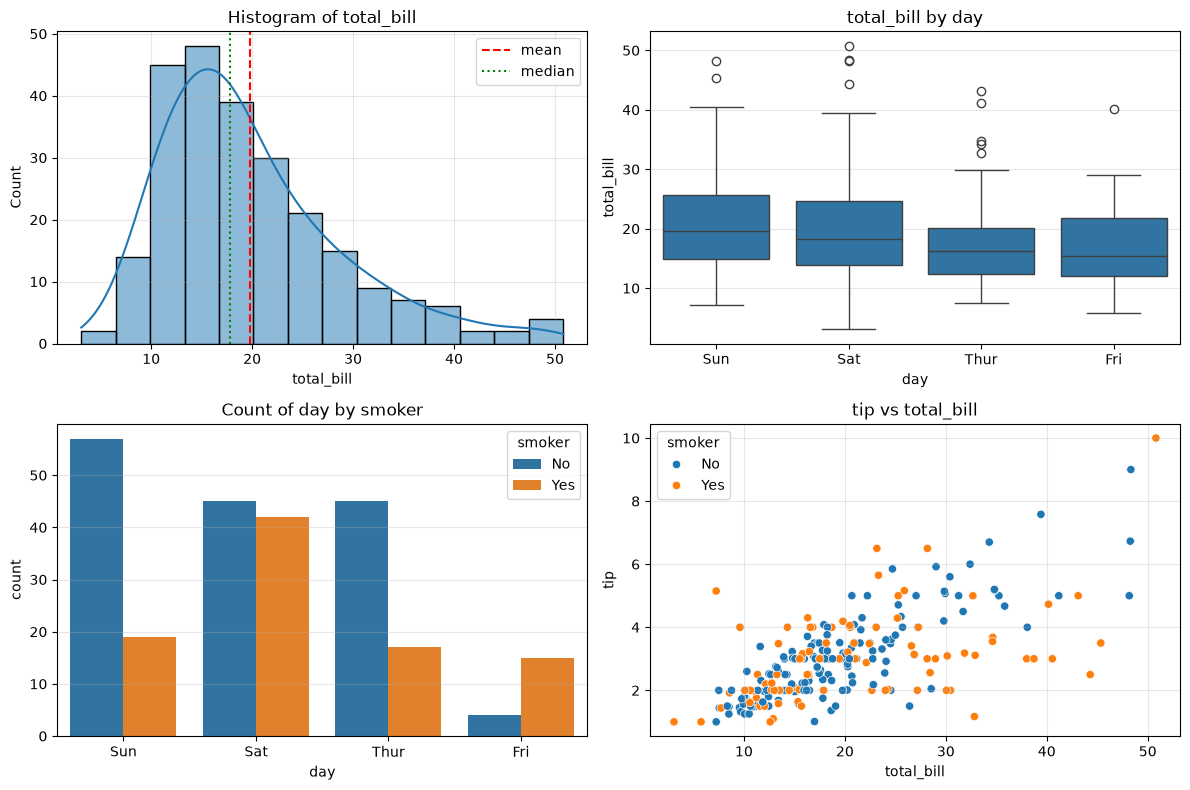

✍️ total_bill: mean=19.79 median=17.80 skew=1.13 → เบ้ขวา (หางยาวด้านค่ามาก) · outlier (IQR) 9 ค่า
✍️ ค่ากลางตามกลุ่ม: {'Fri': 15.38, 'Sat': 18.24, 'Sun': 19.63, 'Thur': 16.2}
✍️ correlation(total_bill, tip) = 0.676


In [12]:
NUM_COL = "total_bill"   # ✏️ ตัวเลขที่จะดูการกระจาย
CAT_COL = "day"          # ✏️ หมวดหมู่ที่จะแยกกลุ่ม
X_COL, Y_COL = "total_bill", "tip"   # ✏️ scatter
HUE = "smoker"           # ✏️ ระบายสีตาม (เช่น label) · None ได้

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df[NUM_COL], kde=True, ax=ax[0, 0]); ax[0, 0].set_title(f"Histogram of {NUM_COL}")
ax[0, 0].axvline(df[NUM_COL].mean(), color="r", ls="--", label="mean"); ax[0, 0].axvline(df[NUM_COL].median(), color="g", ls=":", label="median"); ax[0, 0].legend()
sns.boxplot(data=df, x=CAT_COL, y=NUM_COL, ax=ax[0, 1]); ax[0, 1].set_title(f"{NUM_COL} by {CAT_COL}")
sns.countplot(data=df, x=CAT_COL, hue=HUE, ax=ax[1, 0]); ax[1, 0].set_title(f"Count of {CAT_COL}" + (f" by {HUE}" if HUE else ""))
sns.scatterplot(data=df, x=X_COL, y=Y_COL, hue=HUE, ax=ax[1, 1]); ax[1, 1].set_title(f"{Y_COL} vs {X_COL}")
plt.tight_layout(); plt.show()

q1, q3 = df[NUM_COL].quantile([.25, .75]); iqr = q3 - q1
n_out = int(((df[NUM_COL] < q1 - 1.5 * iqr) | (df[NUM_COL] > q3 + 1.5 * iqr)).sum())
print(f"✍️ {NUM_COL}: mean={df[NUM_COL].mean():.2f} median={df[NUM_COL].median():.2f} skew={df[NUM_COL].skew():.2f} "
      f"→ {'เบ้ขวา (หางยาวด้านค่ามาก)' if df[NUM_COL].skew() > 0.5 else 'เบ้ซ้าย' if df[NUM_COL].skew() < -0.5 else 'ค่อนข้างสมมาตร'} · outlier (IQR) {n_out} ค่า")
print("✍️ ค่ากลางตามกลุ่ม:", df.groupby(CAT_COL)[NUM_COL].median().round(2).to_dict())
print(f"✍️ correlation({X_COL}, {Y_COL}) = {df[X_COL].corr(df[Y_COL]):.3f}")

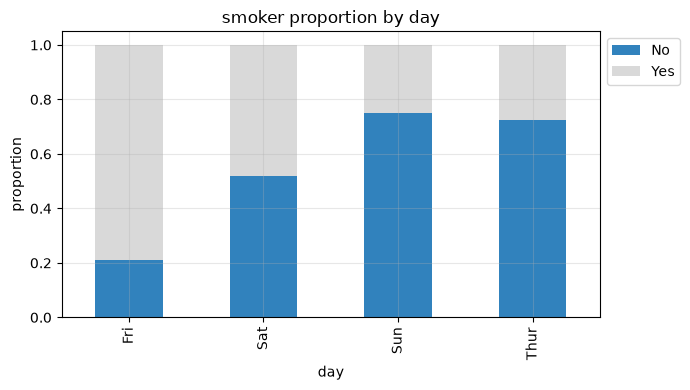

smoker,No,Yes
day,,
Fri,0.2110,0.7890
Sat,0.5170,0.4830
Sun,0.7500,0.2500
Thur,0.7260,0.2740


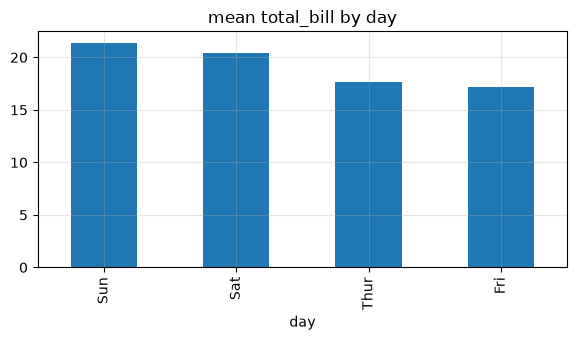

In [13]:
# สัดส่วนคลาสในแต่ละกลุ่ม (stacked bar 100%) — เหมาะกับ "สัดส่วน label ตามหมวด"
STACK_GROUP, STACK_CLASS = "day", "smoker"     # ✏️ กลุ่ม (แกน x), คลาสที่จะดูสัดส่วน
ct = pd.crosstab(df[STACK_GROUP], df[STACK_CLASS], normalize="index")
ct.plot(kind="bar", stacked=True, figsize=(7, 4), colormap="tab20c"); plt.ylabel("proportion")
plt.title(f"{STACK_CLASS} proportion by {STACK_GROUP}"); plt.legend(bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()
display(ct.round(3))

# bar ค่าเฉลี่ยตามกลุ่ม (เรียงมาก → น้อย)
df.groupby(STACK_GROUP)[NUM_COL].mean().sort_values(ascending=False).plot(kind="bar", figsize=(6, 3.5), title=f"mean {NUM_COL} by {STACK_GROUP}")
plt.tight_layout(); plt.show()

## §10 Correlation heatmap (+ คู่ที่สัมพันธ์สูง)
r ใกล้ ±1 = สัมพันธ์เชิงเส้นแรง · |r| < 0.3 อ่อน · **correlation ≠ causation** และวัดแค่เชิงเส้น · คู่ predictor ที่ |r| สูง = multicollinearity

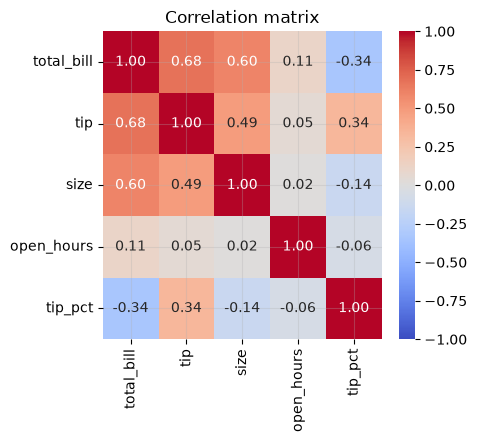

คู่ที่สัมพันธ์กันมากที่สุด:


,var1,var2,r,|r|
1,total_bill,tip,0.6757,0.6757
2,total_bill,size,0.5983,0.5983
7,tip,size,0.4893,0.4893
9,tip,tip_pct,0.3424,0.3424
4,total_bill,tip_pct,-0.3386,0.3386
14,size,tip_pct,-0.1429,0.1429
3,total_bill,open_hours,0.1116,0.1116
19,open_hours,tip_pct,-0.0603,0.0603


✍️ ตัวแปรที่สัมพันธ์กับ tip มากสุด: total_bill (r=0.676), size (r=0.489), tip_pct (r=0.342)


In [14]:
corr = df[[c for c in num_cols(df) if c != ID_COL]].corr()     # ไม่เอา id
plt.figure(figsize=(1 + 0.7 * len(corr), 0.6 * len(corr) + 1))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1); plt.title("Correlation matrix"); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("r").reset_index()
pairs.columns = ["var1", "var2", "r"]
pairs["|r|"] = pairs["r"].abs()
print("คู่ที่สัมพันธ์กันมากที่สุด:"); display(pairs.sort_values("|r|", ascending=False).head(8))
if TARGET in corr:
    tc = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
    print(f"✍️ ตัวแปรที่สัมพันธ์กับ {TARGET} มากสุด: " + ", ".join(f"{k} (r={v:.3f})" for k, v in tc.head(3).items()))
# pairplot (ช้าถ้าคอลัมน์เยอะ): sns.pairplot(df, vars=num_cols(df)[:4], hue=HUE); plt.show()

**✍️ คำตอบ §9–10:** กราฟ … แสดงว่า … (บอกรูปร่าง/ค่ากลาง/การกระจาย/outlier หรือความต่างระหว่างกลุ่ม) · ตัวแปร … สัมพันธ์กับ … มากสุด (r = …) เชิงบวก/ลบ แต่ไม่ได้แปลว่าเป็นสาเหตุ

## §11 Save ผลลัพธ์ (ถ้าโจทย์ให้ส่งไฟล์)

In [15]:
OUT_PATH = "t01_result.csv"     # ✏️ ชื่อไฟล์ผลลัพธ์
df.to_csv(OUT_PATH, index=False)
print("saved", OUT_PATH, df.shape)

saved t01_result.csv (244, 13)
